# Chapter 07 답안 양식. 그래프로 데이터의 이야기를 보여주기

## 제출 정보
- 이름: Jongeun Kim
- GitHub ID: risa0122
- 작성일: 2026-10-21
- 최종 Notebook URL: https://github.com/risa0122/llm-data-analysis-study/blob/main/chapter07/chapter07.ipynb

## 1. 시각화 질문과 그래프 선택

| 질문 | 선택한 그래프 | 선택 이유 |
| --- | --- | --- |
| 카테고리별 completed 주문 금액은 어떻게 다른가? | 가로 막대그래프 | 범주별 금액을 내림차순으로 비교하고 긴 카테고리 이름을 읽기 쉽다. |
| 월별 completed 주문 금액은 어떻게 변하는가? | 선그래프 | 실제 월 간격과 증감을 확인한다. 값이 없는 월은 선을 끊어 0과 구분한다. |
| 전체 상품 가격은 어느 구간에 모여 있는가? | 히스토그램 | 상품 수가 몰린 가격 구간과 극단값을 확인한다. 전체 범위와 확대 범위를 구분한다. |

금액은 `line_total = quantity × unit_price`이며 회계상 매출액·순매출·이익으로 해석하지 않는다. 금액 그래프는 completed 주문 상세, 가격 분포는 전체 상품 마스터를 사용한다. 통화 정보는 별도로 확인되지 않아 축에는 원자료 금액 단위의 배율을 표시했다.

Chapter 06과 같은 Chapter 05 processed 파일을 사용했다. 원본의 카테고리 표기·극단값·날짜를 조용히 수정하지 않는다. 산점도, 익명 상위 고객, 전체 주문 상태는 공식 Notebook의 추가 실습으로 확인한다.

In [1]:
from pathlib import Path
import hashlib
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib import font_manager
from matplotlib.ticker import FuncFormatter, MaxNLocator
from IPython.display import display

current = Path.cwd().resolve()
candidates = [current, current / 'chapter07', current.parent / 'chapter07']
CHAPTER_DIR = next((p for p in candidates if (p / 'chapter07.ipynb').is_file()), None)
if CHAPTER_DIR is None:
    raise FileNotFoundError('chapter07 폴더 또는 저장소 루트에서 실행한다.')
filenames = ['customers_clean.csv', 'products_clean.csv', 'orders_clean.csv', 'order_items_clean.csv']
input_dirs = [CHAPTER_DIR / 'data/processed', CHAPTER_DIR.parent / 'data/processed']
PROCESSED_DIR = next((p for p in input_dirs if all((p / f).is_file() for f in filenames)), None)
if PROCESSED_DIR is None:
    raise FileNotFoundError('Chapter 05 processed CSV 4개가 필요하다.')
IMAGE_DIR = CHAPTER_DIR / 'images'
IMAGE_DIR.mkdir(exist_ok=True)
REPORT_DIR = CHAPTER_DIR / 'reports'
REPORT_DIR.mkdir(exist_ok=True)
AS_OF = pd.Timestamp('2026-10-21')

installed_fonts = {f.name for f in font_manager.fontManager.ttflist}
font_candidates = ['Apple SD Gothic Neo', 'AppleGothic', 'Malgun Gothic', 'NanumGothic', 'Noto Sans CJK KR']
selected_font = next((f for f in font_candidates if f in installed_fonts), None)
if selected_font is None:
    raise RuntimeError('한글 폰트를 찾지 못했다. 폰트를 설치한 뒤 다시 실행한다.')
plt.rcParams.update({'font.family': selected_font, 'axes.unicode_minus': False,
                     'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False,
                     'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.facecolor': 'white'})
pd.set_option('display.max_columns', 12)
pd.set_option('display.max_colwidth', 75)
pd.set_option('display.float_format', lambda value: f'{value:,.2f}')
BLUE, GREY, RED = '#286A93', '#8A9199', '#B44336'
million = FuncFormatter(lambda value, _: f'{value / 1_000_000:g}')
ten_thousand = FuncFormatter(lambda value, _: f'{value / 10_000:g}')
chart_checks = []
saved_figures = []

def save_figure(fig, name):
    fig.savefig(IMAGE_DIR / name, dpi=150, bbox_inches='tight')
    saved_figures.append(name)

print('pandas:', pd.__version__, '/ matplotlib:', matplotlib.__version__)
print('한글 폰트:', selected_font)

pandas: 3.0.5 / matplotlib: 3.11.1
한글 폰트: Apple SD Gothic Neo


In [2]:
# 입력 파일과 주요 키 확인
expected_hashes = {
    'customers_clean.csv': 'f14a59af4a8a900c0b9f72c7fab3367df2ba1e1419f24fb750c1f366174d7d12',
    'products_clean.csv': '6a6632baa5bd328f95587797c9d4fd786b1ad15761484dbe9d6321054ad4b9f7',
    'orders_clean.csv': '8b1faa0ffd2c66313d5de82686e2839509800bfb214a1d0ad80f4ddd92881ecc',
    'order_items_clean.csv': '82389ef808e4f9db56ad76e52fe511b0face3f016cb817cac073a30d7b46d0d2',
}
input_hashes = {name: hashlib.sha256((PROCESSED_DIR / name).read_bytes()).hexdigest() for name in filenames}
assert input_hashes == expected_hashes, '입력 버전이 달라졌다. 수치와 해석을 다시 검토한다.'
customers, products, orders, order_items = [pd.read_csv(PROCESSED_DIR / name) for name in filenames]
datasets = {'customers': customers, 'products': products, 'orders': orders, 'order_items': order_items}
keys = {'customers': 'customer_id', 'products': 'product_id', 'orders': 'order_id', 'order_items': 'order_item_id'}
structure = pd.DataFrame([
    {'데이터': name, '행': len(df), '열': len(df.columns), '키 결측': int(df[keys[name]].isna().sum()),
     '키 중복': int(df[keys[name]].duplicated().sum())} for name, df in datasets.items()
])
assert structure[['키 결측', '키 중복']].eq(0).all().all()
for frame, columns in [(products, ['price']), (order_items, ['quantity', 'unit_price', 'line_total'])]:
    for column in columns:
        assert pd.api.types.is_numeric_dtype(frame[column])
        assert np.isfinite(frame[column]).all()
assert products['price'].gt(0).all()
assert order_items['quantity'].gt(0).all() and order_items['quantity'].mod(1).eq(0).all()
assert order_items['unit_price'].ge(0).all()
assert order_items['line_total'].eq(order_items['quantity'] * order_items['unit_price']).all()
orders['order_date'] = pd.to_datetime(orders['order_date'], errors='coerce')
display(structure)
print('Chapter 05 processed 버전 일치:', input_hashes == expected_hashes)

,데이터,행,열,키 결측,키 중복
0,customers,150,6,0,0
1,products,96,4,0,0
2,orders,300,7,0,0
3,order_items,752,6,0,0


Chapter 05 processed 버전 일치: True


In [3]:
# completed 범위와 미연결 자료 분리
order_sales = order_items.merge(
    orders[['order_id', 'customer_id', 'order_date', 'order_status']],
    on='order_id', how='left', validate='many_to_one', indicator='order_match')
assert len(order_sales) == len(order_items)
unmatched_orders = order_sales.loc[order_sales['order_match'].eq('left_only')].copy()
completed_order_sales = order_sales.loc[order_sales['order_status'].eq('completed')].copy()
sales_items = completed_order_sales.merge(
    products[['product_id', 'category', 'price']], on='product_id', how='left',
    validate='many_to_one', indicator='product_match')
assert len(sales_items) == len(completed_order_sales)
assert sales_items['order_item_id'].is_unique
sales_items['category'] = sales_items['category'].fillna('카테고리 미확인')
completed_ids = orders.loc[orders['order_status'].eq('completed'), 'order_id']
source_completed = order_items.loc[order_items['order_id'].isin(completed_ids)].copy()
source_total = (source_completed['quantity'] * source_completed['unit_price']).sum()
assert set(source_completed['order_item_id']) == set(sales_items['order_item_id'])
assert len(source_completed) == len(sales_items)
missing_date_sales = sales_items.loc[sales_items['order_date'].isna()].copy()
valid_date_sales = sales_items.loc[sales_items['order_date'].notna()].copy()
missing_date_total = missing_date_sales['line_total'].sum()
known_customer = sales_items['customer_id'].isin(customers['customer_id'])
quality_scope = pd.DataFrame([
    ['주문 미연결', len(unmatched_orders), unmatched_orders['line_total'].sum(), 'completed 여부를 알 수 없어 금액 분석 제외'],
    ['카테고리 미확인', int(sales_items['product_match'].eq('left_only').sum()),
     sales_items.loc[sales_items['product_match'].eq('left_only'), 'line_total'].sum(), '별도 범주로 총합 유지'],
    ['날짜 미확인', len(missing_date_sales), missing_date_total, '선그래프에서 제외하되 총합 대조에 별도 포함'],
    ['고객 미연결', int((~known_customer).sum()), sales_items.loc[~known_customer, 'line_total'].sum(), '전체 금액에는 포함, 상위 고객 비교에서는 제외'],
    ['작성일 이후 날짜', int(valid_date_sales['order_date'].gt(AS_OF).sum()),
     valid_date_sales.loc[valid_date_sales['order_date'].gt(AS_OF), 'line_total'].sum(), '날짜를 수정하지 않고 그래프에서 별도 표시'],
], columns=['확인 사항', '상세 행', '금액', '처리 기준'])
display(quality_scope)
print('completed 주문표:', len(completed_ids), '/ 상세 존재:', sales_items['order_id'].nunique(), '/ 상세:', len(sales_items))
print('상세 없는 completed 주문:', int((~completed_ids.isin(sales_items['order_id'])).sum()), '건: 금액 0으로 간주하지 않음')
print('원본 completed 금액:', f'{source_total:,.0f}')
print('문제 유형은 겹칠 수 있으므로 미확인 금액을 서로 더하지 않는다.')

,확인 사항,상세 행,금액,처리 기준
0,주문 미연결,2,"922,000.00",completed 여부를 알 수 없어 금액 분석 제외
1,카테고리 미확인,16,"4,015,000.00",별도 범주로 총합 유지
2,날짜 미확인,6,"1,903,000.00",선그래프에서 제외하되 총합 대조에 별도 포함
3,고객 미연결,1,"376,000.00","전체 금액에는 포함, 상위 고객 비교에서는 제외"
4,작성일 이후 날짜,3,"909,000.00",날짜를 수정하지 않고 그래프에서 별도 표시


completed 주문표: 180 / 상세 존재: 179 / 상세: 446
상세 없는 completed 주문: 1 건: 금액 0으로 간주하지 않음
원본 completed 금액: 141,340,000
문제 유형은 겹칠 수 있으므로 미확인 금액을 서로 더하지 않는다.


공식 검증 함수는 주문 미연결 2행에서 중단된다. 현재 자료 전체가 검증을 통과한 것은 아니다. 이번에는 Chapter 06의 기준에 따라 **상태가 확인된 completed 상세만** 제한적으로 시각화한다. 상품 미연결은 별도 범주로 보존한다. 날짜 미확인은 시간 축에 놓을 수 없어 선그래프 밖에서 금액을 대조한다.

총합 일치는 선택한 범위의 계산 검증이지, 미연결·날짜 오류가 해결되었다는 의미는 아니다.

In [4]:
# 그래프 원본 집계와 총합 대조
category_sales = (
    sales_items.groupby('category', as_index=False, dropna=False)
    .agg(total_quantity=('quantity', 'sum'), completed_amount=('line_total', 'sum'))
    .sort_values(['completed_amount', 'category'], ascending=[False, True]).reset_index(drop=True))
category_sales['amount_ratio_pct'] = (category_sales['completed_amount'] / source_total * 100).round(2)
monthly_sales = (
    valid_date_sales.assign(order_month=valid_date_sales['order_date'].dt.to_period('M'))
    .groupby('order_month', as_index=False)
    .agg(completed_amount=('line_total', 'sum'), completed_order_count=('order_id', 'nunique'))
    .sort_values('order_month').reset_index(drop=True))
monthly_sales['average_completed_order_amount'] = monthly_sales['completed_amount'] / monthly_sales['completed_order_count']
calendar = pd.period_range(monthly_sales['order_month'].min(), monthly_sales['order_month'].max(), freq='M')
monthly_plot = monthly_sales.set_index('order_month').reindex(calendar)
monthly_plot.index.name = 'order_month'
monthly_plot['month_start'] = monthly_plot.index.to_timestamp()
monthly_plot['recorded'] = monthly_plot['completed_amount'].notna()
customer_sales = sales_items.groupby('customer_id', as_index=False).agg(
    completed_amount=('line_total', 'sum'), completed_order_count=('order_id', 'nunique'))
validation = pd.DataFrame([
    ['원본 completed', source_total, source_total],
    ['카테고리별', source_total, category_sales['completed_amount'].sum()],
    ['고객별', source_total, customer_sales['completed_amount'].sum()],
    ['유효 날짜 월별', valid_date_sales['line_total'].sum(), monthly_sales['completed_amount'].sum()],
    ['월별 + 날짜 미확인', source_total, monthly_sales['completed_amount'].sum() + missing_date_total],
], columns=['검증 대상', '기준 금액', '집계 금액'])
validation['차이'] = validation['집계 금액'] - validation['기준 금액']
validation['일치'] = validation['차이'].eq(0)
assert validation['일치'].all()
assert monthly_sales['completed_order_count'].sum() == valid_date_sales['order_id'].nunique()
assert monthly_plot.loc[~monthly_plot['recorded'], 'completed_amount'].isna().all()
display(validation)
print('PASS: 선택한 범위의 총합 일치')
print('시간 축에 없는 날짜 미확인 금액:', f'{missing_date_total:,.0f}')
print('관측된 completed 상세가 없는 월:', ', '.join(monthly_plot.index[~monthly_plot['recorded']].astype(str)))

,검증 대상,기준 금액,집계 금액,차이,일치
0,원본 completed,"141,340,000.00","141,340,000.00",0.00,True
1,카테고리별,"141,340,000.00","141,340,000.00",0.00,True
2,고객별,"141,340,000.00","141,340,000.00",0.00,True
3,유효 날짜 월별,"139,437,000.00","139,437,000.00",0.00,True
4,월별 + 날짜 미확인,"141,340,000.00","141,340,000.00",0.00,True


PASS: 선택한 범위의 총합 일치
시간 축에 없는 날짜 미확인 금액: 1,903,000
관측된 completed 상세가 없는 월: 2026-09, 2026-10, 2026-11, 2026-12


## 2. 대표 그래프 1

질문은 카테고리별 completed 주문 금액 비교다. 긴 범주명이 있어 가로 막대를 선택했다. 원본 표기를 유지하고 금액 내림차순으로 정렬한다.

In [5]:
# 카테고리별 금액과 수량 확인
display(category_sales)
print('1위와 2위의 차이:', f"{category_sales.loc[0, 'completed_amount'] - category_sales.loc[1, 'completed_amount']:,.0f}")

,category,total_quantity,completed_amount,amount_ratio_pct
0,패션,290.00,"32,940,000.00",23.31
1,식품,226.00,"25,035,000.00",17.71
2,전자기기,176.00,"21,485,000.00",15.20
3,도서,174.00,"17,663,000.00",12.50
4,뷰티,168.00,"17,103,000.00",12.10
5,스포츠,165.00,"13,237,000.00",9.37
6,생활용품,108.00,"7,001,000.00",4.95
7,카테고리 미확인,34.00,"4,015,000.00",2.84
8,생활 용품,17.00,"2,108,000.00",1.49
9,뷰 티,12.00,"648,000.00",0.46


1위와 2위의 차이: 7,905,000


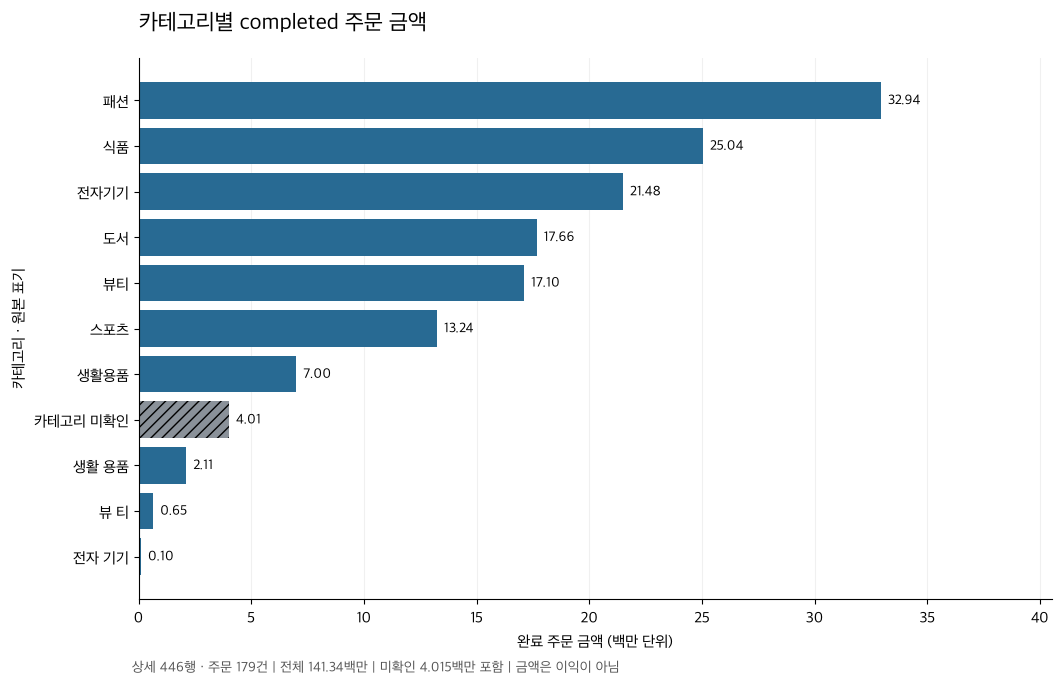

In [6]:
# 카테고리별 completed 금액 시각화
fig1, ax1 = plt.subplots(figsize=(10.5, 6.5), layout='constrained')
bar1 = ax1.barh(category_sales['category'], category_sales['completed_amount'], color=BLUE)
for bar, name in zip(bar1, category_sales['category']):
    if name == '카테고리 미확인':
        bar.set_facecolor(GREY)
        bar.set_hatch('///')
ax1.invert_yaxis()
ax1.set_xlim(0, category_sales['completed_amount'].max() * 1.23)
ax1.set_xlabel('완료 주문 금액 (백만 단위)')
ax1.set_ylabel('카테고리 · 원본 표기')
ax1.set_title('카테고리별 completed 주문 금액', loc='left', fontsize=16, pad=20)
ax1.xaxis.set_major_formatter(million)
ax1.grid(axis='x', alpha=0.18)
ax1.set_axisbelow(True)
ax1.bar_label(bar1, labels=[f'{v / 1_000_000:,.2f}' for v in category_sales['completed_amount']], padding=5, fontsize=10)
fig1.text(0.12, -0.025, '상세 446행 · 주문 179건 | 전체 141.34백만 | 미확인 4.015백만 포함 | 금액은 이익이 아님', fontsize=10, color='#555555')
np.testing.assert_allclose([p.get_width() for p in bar1], category_sales['completed_amount'])
assert [t.get_text() for t in ax1.get_yticklabels()] == category_sales['category'].tolist()
assert ax1.get_xlim()[0] == 0 and ax1.yaxis_inverted()
chart_checks.append(['대표 1 막대', '막대 길이·범주 순서·0 기준축', True])
save_figure(fig1, 'graph01.png')
plt.show()

![대표 그래프 1](images/graph01.png)

### 원본 집계값

completed 금액 합계는 141,340,000이다. 패션 32,940,000, 식품 25,035,000이며 차이는 7,905,000이다. 카테고리 미확인 4,015,000도 포함했다. 그래프의 숫자 레이블은 백만 단위 소수 둘째 자리 반올림이며 정확한 금액은 위 표와 같다.

### 결과 관찰

패션이 전체 금액의 23.31%로 가장 크고, 식품·전자기기가 뒤를 잇는다. 패션의 수량도 290개로 가장 많다. ‘뷰티/뷰 티’, ‘생활용품/생활 용품’, ‘전자기기/전자 기기’는 원본에서 분리되어 있다.

### 나의 해석과 판단

패션은 현재 확인된 completed 금액에서 비중이 큰 범주다. 다만 범주별 금액 차이는 수량과 단가를 함께 봐야 한다. 미확인 범주를 지우면 전체 금액이 줄어들기 때문에 따로 표시했다.

### 업무·분석적 의미

큰 금액을 차지하는 범주부터 판매 수량·주문 단가·상품 수를 나눠 점검할 수 있다. 미확인 범주는 상품 정보 연결을 먼저 보완할 대상이다.

### 한계와 추가 확인 사항

금액 순위는 고객 선호도나 수익성 순위가 아니다. 표기 통합 여부는 상품 분류 기준을 확인한 뒤 결정해야 한다. Chapter 06에서는 세 표기를 통합해도 총합과 1위가 유지됐지만, 이번 본 집계는 processed 원본 표기를 유지했다.

## 3. 대표 그래프 2

질문은 월별 completed 주문 금액의 변화다. 유효한 날짜만 시간 축에 놓고, 관측된 상세가 없는 월은 `NaN`으로 남겨 선을 끊는다. 작성일 이후 날짜는 수정하거나 숨기지 않고 별도 기호로 표시한다.

In [7]:
# 월별 집계표와 관측 여부 확인
monthly_table = monthly_plot[['completed_amount', 'completed_order_count', 'average_completed_order_amount', 'recorded']].copy()
monthly_table.index = monthly_table.index.astype(str)
display(monthly_table.rename_axis('주문 월').reset_index())
print('유효 날짜 금액:', f"{monthly_sales['completed_amount'].sum():,.0f}")
print('날짜 미확인:', len(missing_date_sales), '상세 /', missing_date_sales['order_id'].nunique(), '주문 /', f'{missing_date_total:,.0f}')
print('기록된 completed 주문일 범위:', valid_date_sales['order_date'].min().date(), '~', valid_date_sales['order_date'].max().date())

,주문 월,completed_amount,completed_order_count,average_completed_order_amount,recorded
0,2025-07,"9,561,000.00",11.00,"869,181.82",True
1,2025-08,"9,362,000.00",17.00,"550,705.88",True
2,2025-09,"5,299,000.00",4.00,"1,324,750.00",True
3,2025-10,"12,629,000.00",17.00,"742,882.35",True
4,2025-11,"9,583,000.00",16.00,"598,937.50",True
5,2025-12,"8,581,000.00",12.00,"715,083.33",True
6,2026-01,"8,135,000.00",9.00,"903,888.89",True
7,2026-02,"7,689,000.00",12.00,"640,750.00",True
8,2026-03,"7,247,000.00",13.00,"557,461.54",True
9,2026-04,"11,459,000.00",14.00,"818,500.00",True


유효 날짜 금액: 139,437,000
날짜 미확인: 6 상세 / 2 주문 / 1,903,000
기록된 completed 주문일 범위: 2025-07-02 ~ 2027-01-15


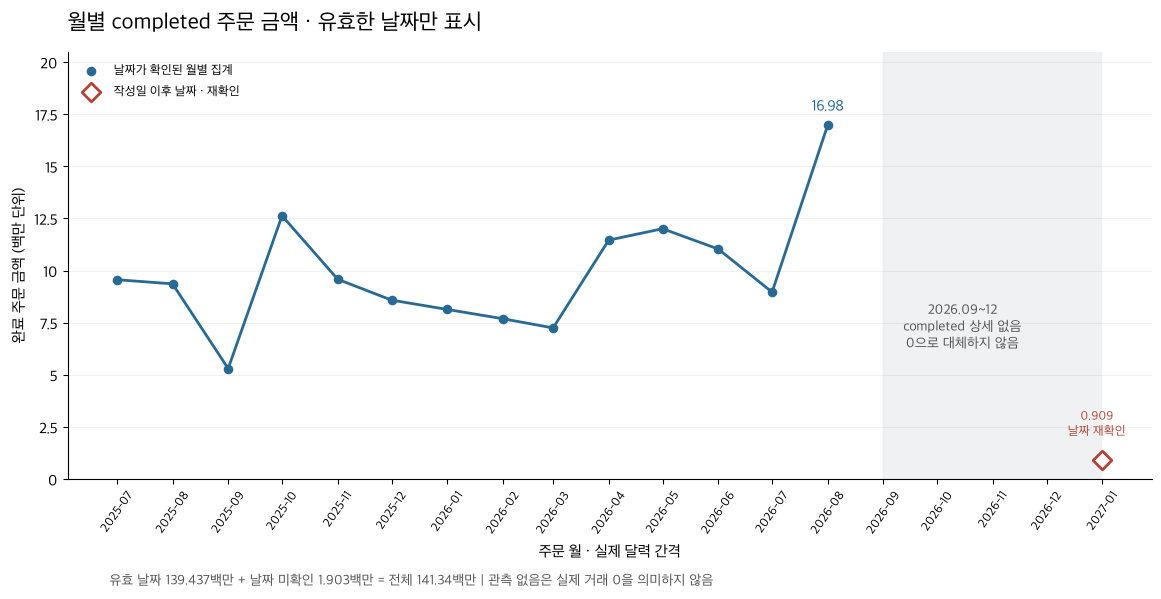

In [8]:
# 비어 있는 월을 0으로 채우지 않는 선그래프
fig2, ax2 = plt.subplots(figsize=(11.5, 5.6), layout='constrained')
x_month = monthly_plot['month_start']
y_month = monthly_plot['completed_amount']
line2, = ax2.plot(x_month, y_month, color=BLUE, linewidth=2)
observed = monthly_plot['recorded']
future = observed & (monthly_plot.index.to_timestamp() > AS_OF)
regular = observed & ~future
ax2.scatter(x_month[regular], y_month[regular], color=BLUE, s=35, label='날짜가 확인된 월별 집계', zorder=3)
ax2.scatter(x_month[future], y_month[future], facecolors='white', edgecolors=RED,
            marker='D', s=90, linewidths=2, label='작성일 이후 날짜 · 재확인', zorder=4)
ax2.axvspan(pd.Timestamp('2026-09-01'), pd.Timestamp('2026-12-31'), color='#EAECEF', alpha=0.7)
ax2.text(pd.Timestamp('2026-10-15'), 6_300_000, '2026.09~12\ncompleted 상세 없음\n0으로 대체하지 않음', ha='center', fontsize=10, color='#555555')
ax2.annotate('16.98', xy=(pd.Timestamp('2026-08-01'), 16_980_000), xytext=(0, 10), textcoords='offset points', ha='center', color=BLUE)
ax2.annotate('0.909\n날짜 재확인', xy=(pd.Timestamp('2027-01-01'), 909_000), xytext=(-4, 18), textcoords='offset points', ha='center', fontsize=9, color=RED)
ax2.set_title('월별 completed 주문 금액 · 유효한 날짜만 표시', loc='left', fontsize=16, pad=16)
ax2.set_xlabel('주문 월 · 실제 달력 간격')
ax2.set_ylabel('완료 주문 금액 (백만 단위)')
ax2.set_ylim(0, 20_500_000)
ax2.set_xticks(x_month)
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
ax2.tick_params(axis='x', rotation=55, labelsize=9)
ax2.yaxis.set_major_formatter(million)
ax2.grid(axis='y', alpha=0.18)
ax2.legend(loc='upper left', fontsize=9, frameon=False)
fig2.text(0.09, -0.035, '유효 날짜 139.437백만 + 날짜 미확인 1.903백만 = 전체 141.34백만 | 관측 없음은 실제 거래 0을 의미하지 않음', fontsize=10, color='#555555')
np.testing.assert_allclose(line2.get_ydata(), y_month.to_numpy(), equal_nan=True)
np.testing.assert_allclose(line2.get_xdata(orig=False), mdates.date2num(x_month.to_numpy()))
assert x_month.is_monotonic_increasing
assert int(np.isnan(line2.get_ydata()).sum()) == int((~observed).sum())
chart_checks.append(['대표 2 선', '선의 x·y 값·시간 간격·NaN 단절', True])
save_figure(fig2, 'graph02.png')
plt.show()

![대표 그래프 2](images/graph02.png)

### 원본 집계값

유효 날짜 금액은 139,437,000이다. 날짜 미확인 6행·2건의 1,903,000을 더하면 원본 completed 합계 141,340,000과 같다. 2026년 8월은 16,980,000·15건, 7월은 8,966,000·8건이다. 8월 주문당 금액은 1,132,000, 7월은 1,120,750이다.

### 결과 관찰

날짜가 확인된 월 중 2026년 8월 금액이 가장 크다. 7월 대비 주문 건수는 8건에서 15건으로 늘었고 주문당 금액은 비슷하다. 2026년 9~12월에는 관측된 completed 상세가 없다. 2027년 1월에는 909,000이 기록되어 있으나 작성일 이후 날짜다.

### 나의 해석과 판단

7~8월 금액 차이는 주문당 금액보다 주문 수 차이가 큰 모습이다. 이는 `금액 = 주문 수 × 주문당 평균 금액`의 분해이며 원인을 설명한 것은 아니다. 빈 월을 0으로 채우거나 선으로 건너 연결하면 급락·회복이 실제로 관측된 것처럼 보일 수 있어 선을 끊었다.

### 업무·분석적 의미

금액 변화를 볼 때 주문 건수와 주문당 금액을 함께 확인하면 후속 분석 대상을 좁힐 수 있다. 먼저 날짜 오류·누락과 기간별 수집 범위를 확인한 뒤 카테고리별 변화도 비교한다.

### 한계와 추가 확인 사항

첫 달의 관측일은 2025-07-02이며 마지막 날짜는 2027-01-15다. 파일만으로 각 달이 완전히 수집됐는지는 확인할 수 없다. 미래 날짜와 미확인 날짜를 정정하기 전에는 지속 성장·계절성·마케팅 효과를 판단하지 않는다. 거래가 기록되지 않은 월을 실제 0이라고 단정하지 않는다.

## 4. 대표 그래프 3

질문은 전체 상품 마스터의 가격 분포다. 주문 여부와 무관한 상품 96개가 대상이다. 전체 범위를 먼저 보여 주고, 0~200,000 범위를 별도 패널로 확대한다. 극단값을 삭제하거나 두 패널의 축이 같다고 보이게 하지 않는다.

In [9]:
# 가격 요약과 히스토그램 구간별 상품 수
prices = products['price'].to_numpy()
zoom_prices = prices[prices <= 200_000]
full_edges = np.linspace(0, 10_000_000, 21)
zoom_edges = np.linspace(0, 200_000, 21)
assert prices.min() >= full_edges[0] and prices.max() <= full_edges[-1]
full_counts, _ = np.histogram(prices, bins=full_edges)
zoom_counts, _ = np.histogram(zoom_prices, bins=zoom_edges)
price_summary = pd.DataFrame({
    '지표': ['전체 상품 수', '최솟값', '중앙값', '평균', '최댓값', '200,000 이하 상품 수'],
    '값': [len(prices), prices.min(), np.median(prices), prices.mean(), prices.max(), len(zoom_prices)]})
bin_table = pd.DataFrame({
    '전체 범위 구간': [f'{a:,.0f}~{b:,.0f}' for a,b in zip(full_edges[:-1],full_edges[1:])],
    '상품 수': full_counts,
    '확대 범위 구간': [f'{a:,.0f}~{b:,.0f}' for a,b in zip(zoom_edges[:-1],zoom_edges[1:])],
    '확대 상품 수': zoom_counts,
})
display(price_summary)
display(bin_table)
print('구간은 왼쪽 포함·오른쪽 제외이며 마지막 구간만 오른쪽도 포함한다.')
assert full_counts.sum() == len(products)
assert zoom_counts.sum() + (prices > 200_000).sum() == len(products)

,지표,값
0,전체 상품 수,96.00
1,최솟값,"5,000.00"
2,중앙값,"94,500.00"
3,평균,"204,895.82"
4,최댓값,"9,999,999.00"
5,"200,000 이하 상품 수",95.00


,전체 범위 구간,상품 수,확대 범위 구간,확대 상품 수
0,"0~500,000",95,"0~10,000",1
1,"500,000~1,000,000",0,"10,000~20,000",5
2,"1,000,000~1,500,000",0,"20,000~30,000",6
3,"1,500,000~2,000,000",0,"30,000~40,000",5
4,"2,000,000~2,500,000",0,"40,000~50,000",5
5,"2,500,000~3,000,000",0,"50,000~60,000",7
6,"3,000,000~3,500,000",0,"60,000~70,000",1
7,"3,500,000~4,000,000",0,"70,000~80,000",10
8,"4,000,000~4,500,000",0,"80,000~90,000",5
9,"4,500,000~5,000,000",0,"90,000~100,000",6


구간은 왼쪽 포함·오른쪽 제외이며 마지막 구간만 오른쪽도 포함한다.


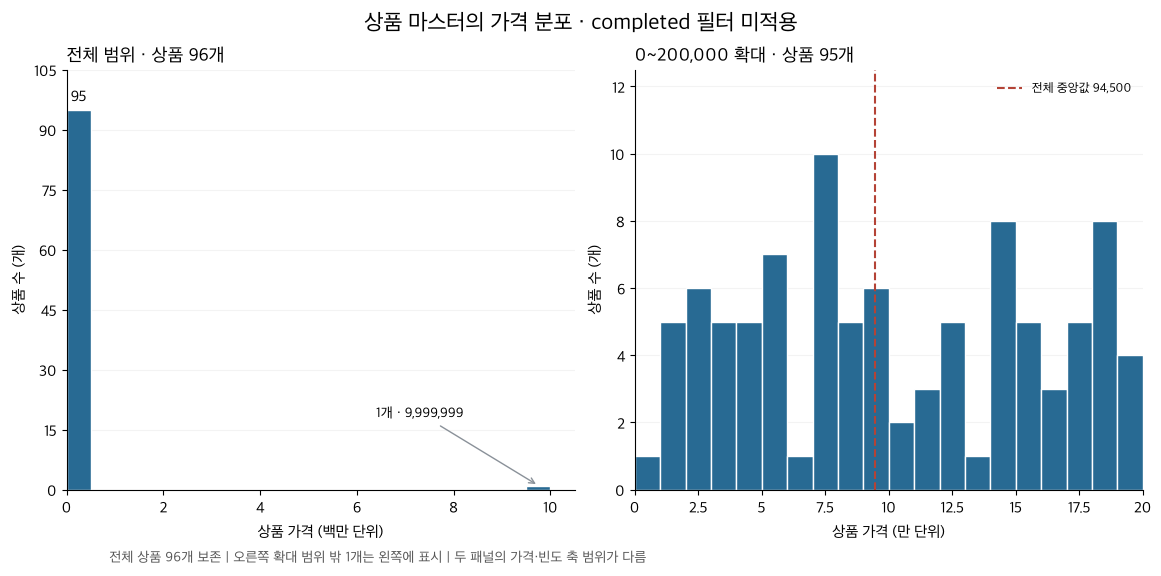

In [10]:
# 전체 가격 분포와 별도 확대 보기
fig3, axes3 = plt.subplots(1, 2, figsize=(11.5, 5.4), layout='constrained')
n_full, edges_full, hist_full = axes3[0].hist(prices, bins=full_edges, color=BLUE, edgecolor='white')
n_zoom, edges_zoom, hist_zoom = axes3[1].hist(zoom_prices, bins=zoom_edges, color=BLUE, edgecolor='white')
axes3[0].set_title('전체 범위 · 상품 96개', loc='left')
axes3[0].set_xlabel('상품 가격 (백만 단위)')
axes3[0].xaxis.set_major_formatter(million)
axes3[0].set_xlim(0, 10_500_000)
axes3[0].set_ylim(0, 105)
axes3[0].text(250_000, 97, '95', ha='center')
axes3[0].annotate('1개 · 9,999,999', xy=(9_750_000, 1), xytext=(7_300_000, 18),
                  arrowprops={'arrowstyle': '->', 'color': GREY}, ha='center', fontsize=10)
axes3[1].set_title('0~200,000 확대 · 상품 95개', loc='left')
axes3[1].set_xlabel('상품 가격 (만 단위)')
axes3[1].xaxis.set_major_formatter(ten_thousand)
axes3[1].set_xlim(0, 200_000)
axes3[1].set_ylim(bottom=0, top=max(zoom_counts) * 1.25)
axes3[1].axvline(np.median(prices), color=RED, linestyle='--', label='전체 중앙값 94,500')
axes3[1].legend(fontsize=9, frameon=False)
for ax in axes3:
    ax.set_ylabel('상품 수 (개)')
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.grid(axis='y', alpha=0.15)
    ax.set_axisbelow(True)
fig3.suptitle('상품 마스터의 가격 분포 · completed 필터 미적용', fontsize=16)
fig3.text(0.09, -0.03, '전체 상품 96개 보존 | 오른쪽 확대 범위 밖 1개는 왼쪽에 표시 | 두 패널의 가격·빈도 축 범위가 다름', fontsize=10, color='#555555')
np.testing.assert_array_equal(n_full, full_counts)
np.testing.assert_array_equal(n_zoom, zoom_counts)
np.testing.assert_array_equal([p.get_height() for p in hist_full], full_counts)
np.testing.assert_array_equal([p.get_height() for p in hist_zoom], zoom_counts)
np.testing.assert_allclose(edges_full, full_edges)
np.testing.assert_allclose(edges_zoom, zoom_edges)
chart_checks.append(['대표 3 분포', '전체·확대 구간 빈도와 막대 높이·96개 보존', True])
save_figure(fig3, 'graph03.png')
plt.show()

,bins,전체 수,전체 첫 구간,전체 마지막 구간,확대 수,확대 최대 빈도
0,10,96,95,1,95,13
1,20,96,95,1,95,10
2,30,96,95,1,95,8


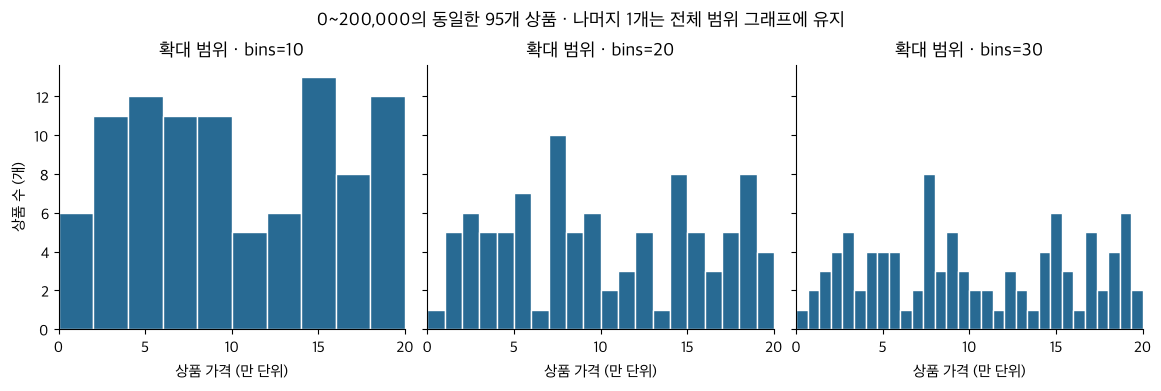

In [11]:
# 같은 상품 자료에서 구간 수에 따른 모양 비교
fig_bins, axes_bins = plt.subplots(1, 3, figsize=(11.5, 3.8), sharey=True, layout='constrained')
bins_rows = []
for ax, bin_count in zip(axes_bins, [10, 20, 30]):
    full_n, _ = np.histogram(prices, bins=bin_count, range=(0, 10_000_000))
    zoom_n, _, patches = ax.hist(zoom_prices, bins=bin_count, range=(0, 200_000), color=BLUE, edgecolor='white')
    assert int(full_n.sum()) == 96 and int(zoom_n.sum()) == 95
    bins_rows.append([bin_count, int(full_n.sum()), int(full_n[0]), int(full_n[-1]), int(zoom_n.sum()), int(zoom_n.max())])
    ax.set_title(f'확대 범위 · bins={bin_count}')
    ax.set_xlim(0, 200_000)
    ax.set_ylim(bottom=0)
    ax.xaxis.set_major_formatter(ten_thousand)
    ax.set_xlabel('상품 가격 (만 단위)')
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
axes_bins[0].set_ylabel('상품 수 (개)')
fig_bins.suptitle('0~200,000의 동일한 95개 상품 · 나머지 1개는 전체 범위 그래프에 유지')
display(pd.DataFrame(bins_rows, columns=['bins', '전체 수', '전체 첫 구간', '전체 마지막 구간', '확대 수', '확대 최대 빈도']))
save_figure(fig_bins, 'graph03_bins.png')
plt.show()

![대표 그래프 3](images/graph03.png)

### 원본 집계값

전체 상품은 96개다. 최솟값 5,000, 중앙값 94,500, 평균 약 204,896, 최댓값 9,999,999이다. 95개는 200,000 이하이고 나머지 1개는 9,999,999다. 히스토그램 구간별 빈도의 합계가 각각 전체 96개, 확대 95개와 일치한다.

### 결과 관찰

전체 상품의 98.96%가 200,000 이하에 있다. 전체 축만 보면 대부분이 첫 막대에 모여 중앙 분포가 잘 보이지 않는다. 전체 범위에서 bins를 10·20·30으로 바꿔도 첫 구간 95개, 마지막 구간 1개가 유지된다. 확대 보기의 봉우리 높이는 구간 수에 따라 달라진다.

### 나의 해석과 판단

평균이 중앙값보다 큰 것은 매우 큰 가격값의 영향을 받는 모습이다. 극단값을 숨기지 않으면서 나머지 분포를 볼 수 있도록 전체·확대 패널을 분리했다. 한 구간 설정에서 높아 보이는 막대를 대표 가격대라고 단정하지 않는다.

### 업무·분석적 의미

상품 가격대를 검토할 때 평균만 보지 않고 중앙값·구간별 상품 수를 함께 확인할 수 있다. 9,999,999의 가격은 원자료와 상품 등록 기준을 먼저 확인할 항목이다.

### 한계와 추가 확인 사항

이 분포는 상품 구성이지 판매량이나 고객 선호 분포가 아니다. 높은 가격이 실제 고가 상품인지 입력 오류인지는 확정할 수 없다. 확대 그래프는 95개만 보여 주므로 전체 그래프와 함께 해석해야 한다. 상품 마스터 가격과 실제 주문 단가도 구분해야 한다.

## 5. 그래프 정확성 점검

- [x] 그래프 값과 집계표 값 일치
- [x] 축 이름 확인
- [x] 단위 확인
- [x] 범례 확인
- [x] 날짜 정렬 확인
- [x] 과장될 수 있는 축 범위 확인
- [x] 제목이 분석 범위를 정확히 표현

대표 그래프는 막대·선·히스토그램 객체에 실제로 전달된 값과 원본 표를 비교했다. 추가 실습도 그래프를 그리기 전에 집계표를 확인한다. 아래 PASS는 계산·표시 범위의 검증이며 원본 품질 전체의 통과를 뜻하지 않는다.

In [12]:
# 대표 그래프의 실제 표시 값 검증
display(pd.DataFrame(chart_checks, columns=['그래프', '검증 내용', '일치']))
assert len(chart_checks) == 3 and all(row[2] for row in chart_checks)
print('PASS: 대표 그래프 3개의 실제 표시 값과 집계표 일치')
print('월별 선의 빈 구간:', int((~monthly_plot['recorded']).sum()), '/ 전체 히스토그램:', int(full_counts.sum()), '개')

,그래프,검증 내용,일치
0,대표 1 막대,막대 길이·범주 순서·0 기준축,True
1,대표 2 선,선의 x·y 값·시간 간격·NaN 단절,True
2,대표 3 분포,전체·확대 구간 빈도와 막대 높이·96개 보존,True


PASS: 대표 그래프 3개의 실제 표시 값과 집계표 일치
월별 선의 빈 구간: 4 / 전체 히스토그램: 96 개


**추가 실습: 상품 가격·수량, 익명 상위 고객, 주문 상태**

산점도는 상품 마스터에 연결된 completed 구매 상품만 사용한다. 가격을 알 수 없는 상품 미연결 상세는 이 그래프에서만 제외한다. 상위 고객은 고객표와 연결된 고객 중 금액 상위 10명을 순위 라벨로 표시한다. 주문 상태 그래프는 전체 주문 300건을 사용한다.

In [13]:
# 보조 그래프의 집계표와 공개 범위
product_sales = (
    sales_items.loc[sales_items['product_match'].eq('both')]
    .groupby(['product_id', 'price'], as_index=False)
    .agg(completed_quantity=('quantity', 'sum'), completed_amount=('line_total', 'sum'))
    .sort_values('price').reset_index(drop=True))
known_sales = customer_sales.loc[customer_sales['customer_id'].isin(customers['customer_id'])].copy()
known_sales = known_sales.sort_values(['completed_amount', 'customer_id'], ascending=[False, True])
top_customers = known_sales.head(10).copy()
top_customers['고객'] = [f'고객 {i:02d}' for i in range(1, len(top_customers) + 1)]
public_top = top_customers[['고객', 'completed_amount', 'completed_order_count']].reset_index(drop=True)
order_status = orders.groupby('order_status', as_index=False).agg(order_count=('order_id', 'nunique'))
order_status = order_status.sort_values('order_count', ascending=False).reset_index(drop=True)
display(product_sales[['price', 'completed_quantity', 'completed_amount']].describe())
display(public_top)
display(order_status)
assert product_sales['completed_amount'].sum() + sales_items.loc[sales_items['product_match'].ne('both'), 'line_total'].sum() == source_total
assert known_sales['completed_amount'].sum() + sales_items.loc[~known_customer, 'line_total'].sum() == source_total
assert order_status['order_count'].sum() == len(orders)
print('산점도 상품 수:', len(product_sales), '/ 전체 고객표 연결 구매 고객:', len(known_sales))

,price,completed_quantity,completed_amount
count,95.00,95.00,95.00
mean,"206,610.52",14.12,"1,445,526.32"
std,"1,017,075.64",9.10,"1,263,065.84"
min,"5,000.00",2.00,"63,000.00"
25%,"53,500.00",8.50,"499,500.00"
50%,"96,000.00",13.00,"1,218,000.00"
75%,"153,500.00",18.00,"1,952,000.00"
max,"9,999,999.00",70.00,"6,771,000.00"


,고객,completed_amount,completed_order_count
0,고객 01,"6,702,000.00",3
1,고객 02,"5,204,000.00",4
2,고객 03,"4,311,000.00",3
3,고객 04,"4,001,000.00",4
4,고객 05,"3,977,000.00",6
5,고객 06,"3,966,000.00",2
6,고객 07,"3,808,000.00",4
7,고객 08,"3,656,000.00",4
8,고객 09,"3,201,000.00",4
9,고객 10,"3,109,000.00",3


,order_status,order_count
0,completed,180
1,cancelled,63
2,refunded,57


산점도 상품 수: 95 / 전체 고객표 연결 구매 고객: 98


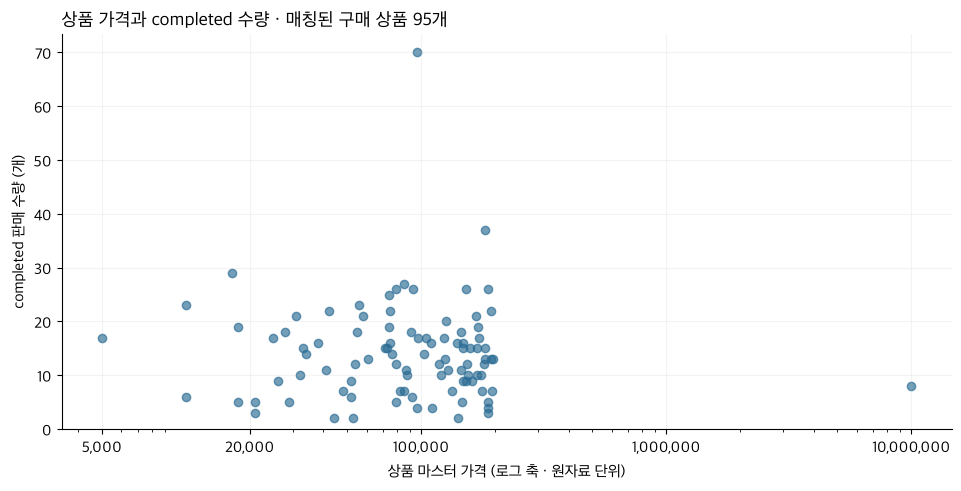

In [14]:
# 상품 가격과 completed 수량의 관계
fig4, ax4 = plt.subplots(figsize=(9.5, 4.8), layout='constrained')
scatter4 = ax4.scatter(product_sales['price'], product_sales['completed_quantity'], color=BLUE, alpha=0.65, s=36)
ax4.set_xscale('log')
ax4.set_xlabel('상품 마스터 가격 (로그 축 · 원자료 단위)')
ax4.set_ylabel('completed 판매 수량 (개)')
ax4.set_ylim(bottom=0)
ax4.set_title(f'상품 가격과 completed 수량 · 매칭된 구매 상품 {len(product_sales)}개', loc='left')
ax4.set_xticks([5_000, 20_000, 100_000, 1_000_000, 10_000_000])
ax4.xaxis.set_major_formatter(FuncFormatter(lambda value, _: f'{value:,.0f}'))
ax4.grid(alpha=0.15)
np.testing.assert_allclose(scatter4.get_offsets(), product_sales[['price', 'completed_quantity']].to_numpy())
chart_checks.append(['보조 산점도', '좌표·매칭 범위·로그 축 표시', True])
save_figure(fig4, 'additional_scatter.png')
plt.show()

산점도의 한 점은 매칭된 구매 상품 하나다. 큰 가격값 때문에 나머지 점이 뭉치는 것을 줄이려고 가격 축을 로그로 표시했다. 같은 가로 간격은 같은 가격 차이가 아니라 같은 배율이다. 미판매 상품과 상품 미연결은 포함되지 않으므로 전체 상품의 가격 효과를 추정한 그래프가 아니다. 상품 가격을 판매 수량의 원인으로 판단하지 않는다.

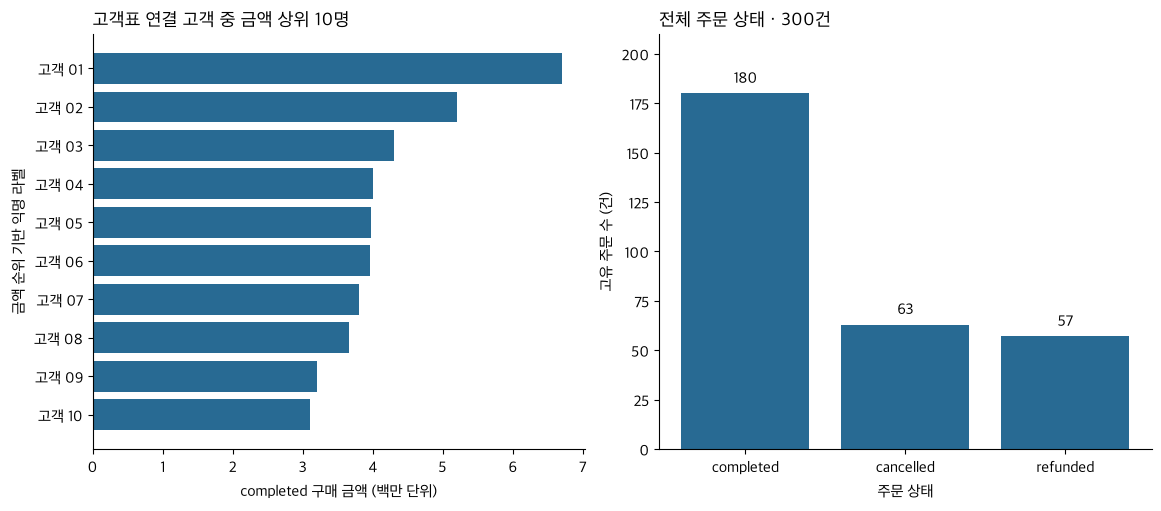

In [15]:
# 상위 고객은 익명 순위로 표시하고 주문 상태는 전체 주문으로 확인
fig5, (ax5a, ax5b) = plt.subplots(1, 2, figsize=(11.5, 5), layout='constrained')
top_bars = ax5a.barh(public_top['고객'], public_top['completed_amount'], color=BLUE)
ax5a.invert_yaxis()
ax5a.set_xlim(left=0)
ax5a.set_xlabel('completed 구매 금액 (백만 단위)')
ax5a.set_ylabel('금액 순위 기반 익명 라벨')
ax5a.set_title('고객표 연결 고객 중 금액 상위 10명', loc='left')
ax5a.xaxis.set_major_formatter(million)
status_bars = ax5b.bar(order_status['order_status'], order_status['order_count'], color=BLUE)
ax5b.set_ylim(0, 210)
ax5b.set_xlabel('주문 상태')
ax5b.set_ylabel('고유 주문 수 (건)')
ax5b.set_title('전체 주문 상태 · 300건', loc='left')
ax5b.bar_label(status_bars, padding=4)
np.testing.assert_allclose([p.get_width() for p in top_bars], public_top['completed_amount'])
np.testing.assert_allclose([p.get_height() for p in status_bars], order_status['order_count'])
assert all(t.get_text().startswith('고객 ') for t in ax5a.get_yticklabels())
chart_checks.append(['보조 고객·상태', '집계값·익명 라벨·전체 주문 300건', True])
save_figure(fig5, 'additional_customers_status.png')
plt.show()

상위 고객 그래프에는 이름·원본 고객 ID를 표시하지 않았다. 금액이 높다는 이유만으로 충성 고객으로 부르지 않으며 주문 횟수·관측 기간을 함께 봐야 한다. 전체 주문 상태는 completed 180건, cancelled 63건, refunded 57건이다. 이 건수만으로 취소·환불의 원인을 설명할 수 없다.

### 내가 발견한 시각화 위험 또는 개선점

| 문제 | 오해 가능성 | 수정 방법 | 확인 결과 |
| --- | --- | --- | --- |
| 상품 미연결·날짜 미확인 | 금액을 삭제하면 범주별·월별 합계가 작아짐 | 카테고리 미확인 유지, 날짜 미확인 금액 별도 대조 | 월별 139,437,000 + 미확인 1,903,000 = 전체 141,340,000 |
| 2026년 9~12월 공백 | 0으로 채우면 실제 급락처럼 보임 | 달력 전체를 만들되 NaN으로 유지 | 선의 빈 구간 4개월 확인 |
| 작성일 이후 날짜 | 미래 거래가 확정된 것처럼 보임 | 빈 마름모와 날짜 재확인 레이블 표시 | 2027년 1월 909,000 별도 표시 |
| 상품 가격 9,999,999 | 전체 선형 축에서 나머지 분포가 가려짐 | 전체와 확대 패널 분리, bins 10·20·30 비교 | 전체 96개·확대 95개 빈도 대조 |
| 카테고리 내부 공백 | 같은 분류일 수 있는 값을 다른 분류로 인식 | 원본 표기임을 명시하고 정정은 보류 | 원본과 총합 유지 |
| 상위 고객·산점도 | 일부 표본을 전체로 일반화하거나 인과로 해석 | 포함 범위·익명 라벨·로그 축 명시 | 공개 라벨과 그래프 좌표 검증 |

**공식 스크립트 재실행 결과**

2026-10-21에 같은 processed CSV를 복사한 별도 폴더에서 `python scripts/run_visualization.py`를 실행했다. 공식 코드는 변경하지 않았다. 결과는 종료 코드 1, `ValueError: 주문 정보와 연결되지 않은 주문 상세가 있습니다: 2행`이었다. 따라서 공식 일괄 실행 성공으로 기록하지 않는다. 이번 Notebook은 미연결을 기록하고 제한된 completed 범위를 명시한 별도 집계·그래프이며, 원자료 품질 정정은 남은 과제다.

### LLM 시각화 검토

- 검토에 사용한 정보: processed 구조, completed 범위, 카테고리·월별 집계와 가격 요약이다. 공개 그래프와 집계표에 고객 이름·원본 고객 ID는 표시하지 않았다.
- Prompt 요지: 과제 요구사항에 맞춰 시각화 질문과 그래프를 작성하고, 집계값 검증과 결과 해석을 포함하도록 요청했다.
- 제안 요약: 정렬된 가로 막대, 빈 월에서 끊기는 선, 전체·확대 히스토그램과 bins 비교를 사용한다. 보조 고객 그래프는 익명화하고 산점도 관계를 인과로 해석하지 않는다.
- 실제 사용 여부: 수정 후 사용.
- 판단 이유: 기존 예제의 선은 관측된 월만 연결하면 공백 기간까지 이어질 수 있다. 전체 가격 히스토그램만으로는 대부분의 상품 분포가 보이지 않는다. 범위와 표본 수를 드러내는 방식으로 수정했다.
- 실행 검증 결과: 그래프 객체의 좌표·막대 높이·구간별 빈도를 집계표와 비교했고 모두 일치했다. 새 커널 재실행에서도 같은 결과가 재현됐다. 이 검증이 원자료의 품질 문제까지 해결했다는 뜻은 아니다.

In [16]:
# 최종 수치·표시 범위·파일 보존 확인
accuracy_checks = pd.DataFrame(chart_checks, columns=['그래프', '검증 내용', '일치'])
assert accuracy_checks['일치'].all()
after_hashes = {name: hashlib.sha256((PROCESSED_DIR / name).read_bytes()).hexdigest() for name in filenames}
assert after_hashes == input_hashes
tables = {'validation': validation, 'category': category_sales, 'monthly': monthly_table.reset_index(),
          'price_bins': bin_table, 'chart_checks': accuracy_checks, 'quality_scope': quality_scope}
for name, table in tables.items():
    path = REPORT_DIR / f'ch07_{name}.csv'
    table.to_csv(path, index=False, encoding='utf-8-sig')
    read_back = pd.read_csv(path)
    pd.testing.assert_frame_equal(table.reset_index(drop=True), read_back, check_dtype=False)
file_check = pd.DataFrame([{'파일': name, '저장 확인': (IMAGE_DIR / name).is_file(),
                           'bytes': (IMAGE_DIR / name).stat().st_size} for name in saved_figures])
assert file_check['저장 확인'].all() and file_check['bytes'].gt(0).all()
display(accuracy_checks)
display(file_check)
print('PASS: 대표 그래프·보조 그래프의 실제 값 검증 / 입력 CSV 4개 보존 / 집계 CSV 재로딩 일치')
print('남은 확인: 미연결, 날짜 누락·미래 날짜, 카테고리 표기, 가격 극단값')

,그래프,검증 내용,일치
0,대표 1 막대,막대 길이·범주 순서·0 기준축,True
1,대표 2 선,선의 x·y 값·시간 간격·NaN 단절,True
2,대표 3 분포,전체·확대 구간 빈도와 막대 높이·96개 보존,True
3,보조 산점도,좌표·매칭 범위·로그 축 표시,True
4,보조 고객·상태,집계값·익명 라벨·전체 주문 300건,True


,파일,저장 확인,bytes
0,graph01.png,True,62313
1,graph02.png,True,116917
2,graph03.png,True,76966
3,graph03_bins.png,True,46641
4,additional_scatter.png,True,58744
5,additional_customers_status.png,True,61379


PASS: 대표 그래프·보조 그래프의 실제 값 검증 / 입력 CSV 4개 보존 / 집계 CSV 재로딩 일치
남은 확인: 미연결, 날짜 누락·미래 날짜, 카테고리 표기, 가격 극단값


## 6. Chapter 07 최종 판단

### 가장 중요한 그래프 1개와 이유

월별 금액 선그래프를 가장 중요하게 봤다. 금액의 크기뿐 아니라 날짜 누락·공백·미래 날짜를 어떻게 처리하느냐에 따라 추세의 인상이 달라지기 때문이다.

### 그래프가 보여 준 사실

확인된 completed 금액에서 패션이 가장 크다. 날짜가 있는 월 중 2026년 8월 금액이 가장 높고, 7월보다 주문 수가 많다. 상품 96개 중 95개는 200,000 이하이며 1개는 9,999,999다.

### 그래프만으로 말할 수 없는 것

패션의 수익성이 가장 높은지, 8월 금액이 마케팅으로 늘었는지, 큰 가격값이 오류인지는 알 수 없다. 빈 월에 실제 거래가 없었다고 단정할 수도 없다. 그래프가 읽기 쉽다는 것과 데이터가 완전하다는 것은 별개다.

### 다음 분석에서 확인할 질문

날짜를 정정하고 관측 기간을 맞춰도 8월의 금액·주문 수 차이가 유지되는가? 카테고리 표기를 통합한 뒤 수량과 주문 단가를 나눠도 금액 순위가 유지되는가? 큰 상품 가격값을 원자료로 확인하면 분포 해석이 달라지는가?

## 최종 체크
- [x] 그래프와 수치를 교차 검증했습니다.
- [x] 관찰과 해석을 구분했습니다.
- [x] 업무적 의미와 한계를 작성했습니다.
- [ ] 최종 Notebook URL을 제출합니다.